# 03 — التقييم على Test set (بمقاييس غير مضللة)

**لماذا Accuracy مضللة هنا؟** في LEVIR-CD نحو 95% من البكسل غير متغيرة؛ نموذج
يصنف كل شيء "بدون تغيير" يحقق Accuracy ≈ 95% دون أن يكتشف أي تغيير. لذلك
نُبلغ عن:

| المقياس | التعريف | لماذا |
|---|---|---|
| Precision / Recall / F1 (change) | TP/(TP+FP) ، TP/(TP+FN) ، التوفيق بينهما | تركز على فئة التغيّر الأهم |
| IoU (change) | TP/(TP+FP+FN) | المقياس القياسي في التجزئة |
| **Mean IoU** | متوسط IoU للفئتين | يمنع اختفاء فئة |
| **Balanced Accuracy** | متوسط recall الفئتين | مقاوم لعدم التوازن |
| **Cohen's Kappa** | (p_o − p_e)/(1 − p_e) | يصحح الاتفاق العشوائي |
| Accuracy | (TP+TN)/total | تُعرض **للمعلومية فقط** |

**العتبة:** التنبؤ = `sigmoid(logits) > threshold`. يمكن ضبط العتبة على
**validation** (الخلية أدناه) بدل اعتبار 0.5.

المنطق الكامل غير التفاعلي: `python evaluate.py --threshold auto`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():   # kernel cwd may be notebooks/
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
from PIL import Image

from src import config
from src.data_discovery import build_samples, download_dataset, load_mask
from src.dataset import EvalTileDataset, samples_for_split
from src.metrics import ConfusionMeter
from src.model import SiameseUNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# اختار أفضل run (أعلى val_iou في checkpoint) وليس الأحدث — حتى لا يلتقط
# دفترُ التدريب التجريبي (run_nb_...) نفسَه بدل النموذج النهائي
runs = sorted(config.OUTPUT_DIR.glob("run_*"))
best_run, best_val = None, -1.0
for r in runs:
    ck_file = r / "best_model.pt"
    if not ck_file.exists():
        continue
    meta = torch.load(ck_file, map_location="cpu", weights_only=False)
    v = float(meta.get("val_iou", -1.0))
    print(f"  {r.name}: epoch {meta.get('epoch')} val_iou {v:.4f}")
    if v > best_val:
        best_run, best_val = r, v
run_dir = best_run
ckpt_path = run_dir / "best_model.pt"
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model = SiameseUNet(in_ch=config.IN_CHANNELS, base=32).to(device)
model.load_state_dict(ckpt["model"]); model.eval()
print(f"\nselected run: {run_dir.name} | checkpoint epoch {ckpt.get('epoch')} | "
      f"val IoU {ckpt.get('val_iou', float('nan')):.4f}")

root = download_dataset()
samples, _ = build_samples(root)
val_s, test_s = samples_for_split(samples, "val"), samples_for_split(samples, "test")
val_ds = EvalTileDataset(val_s, image_size=config.IMAGE_SIZE)
test_ds = EvalTileDataset(test_s, image_size=config.IMAGE_SIZE)
val_dl = DataLoader(val_ds, batch_size=32, num_workers=0)
test_dl = DataLoader(test_ds, batch_size=32, num_workers=0)
print(f"val tiles: {len(val_ds)} | test tiles: {len(test_ds)}")

  run_20261009_193121: epoch 1 val_iou 0.0459
  run_20261009_200513: epoch 40 val_iou 0.5763
  run_20261011_073203: epoch 18 val_iou 0.6098
  run_nb_20261012_120143: epoch 3 val_iou 0.2394
  run_nb_20261012_121210: epoch 3 val_iou 0.2394
  run_nb_20261012_122117: epoch 3 val_iou 0.2394



selected run: run_20261011_073203 | checkpoint epoch 18 | val IoU 0.6098


[data] Downloading / locating dataset 'mdrifaturrahman33/levir-cd-change-detection' ...
[data] kagglehub cache: D:\DEPI Project\.kagglehub_cache


[data] Dataset root: D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1

[data] Detected role folders:
    [   A] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\A
    [   B] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\B
    [mask] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\test\label
    [   A] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\A
    [   B] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\B
    [mask] D:\DEPI Project\.kagglehub_cache\datasets\mdrifaturrahman33\levir-cd-change-detection\versions\1\LEVIR-CD+\train\label


val tiles: 2352 | test tiles: 2384


## 1) ضبط العتبة على validation

In [2]:
THRESHOLDS = [round(t, 2) for t in np.arange(0.30, 0.701, 0.05)]
meters = {t: ConfusionMeter() for t in THRESHOLDS}

with torch.no_grad():
    for batch in val_dl:
        a = batch["a"].to(device); b = batch["b"].to(device)
        logits = model(a, b).float().cpu()
        metas = batch["meta"]
        for j in range(logits.shape[0]):
            vh, vw = int(metas["valid_h"][j]), int(metas["valid_w"][j])
            lg = logits[j, :, :vh, :vw]; yt = batch["mask"][j, :, :vh, :vw]
            for t in THRESHOLDS:
                meters[t].update(lg.unsqueeze(0), yt.unsqueeze(0), t)

rows = [(t, meters[t].metrics()) for t in THRESHOLDS]
print(f"{'thr':>5} | {'F1':>7} | {'IoU':>7} | {'P':>7} | {'R':>7}")
for t, m in rows:
    print(f"{t:5.2f} | {m['f1']:7.4f} | {m['iou']:7.4f} | {m['precision']:7.4f} | {m['recall']:7.4f}")
THRESHOLD = max(rows, key=lambda x: x[1]["f1"])[0]
print(f"\nchosen threshold (best val F1): {THRESHOLD}")

  thr |      F1 |     IoU |       P |       R
 0.30 |  0.7607 |  0.6138 |  0.7484 |  0.7734
 0.35 |  0.7607 |  0.6138 |  0.7577 |  0.7637
 0.40 |  0.7601 |  0.6131 |  0.7660 |  0.7543
 0.45 |  0.7592 |  0.6118 |  0.7739 |  0.7450
 0.50 |  0.7576 |  0.6097 |  0.7813 |  0.7352
 0.55 |  0.7551 |  0.6065 |  0.7886 |  0.7242
 0.60 |  0.7516 |  0.6021 |  0.7960 |  0.7119
 0.65 |  0.7473 |  0.5965 |  0.8042 |  0.6979
 0.70 |  0.7418 |  0.5895 |  0.8140 |  0.6813

chosen threshold (best val F1): 0.3


## 2) التقييم النهائي على test (مرة واحدة)

In [3]:
meter = ConfusionMeter()
with torch.no_grad():
    for batch in test_dl:
        a = batch["a"].to(device); b = batch["b"].to(device)
        logits = model(a, b).float().cpu()
        metas = batch["meta"]
        for j in range(logits.shape[0]):
            vh, vw = int(metas["valid_h"][j]), int(metas["valid_w"][j])
            meter.update(logits[j, :, :vh, :vw], batch["mask"][j, :, :vh, :vw], THRESHOLD)
m = meter.metrics()
total = m["tp"] + m["fp"] + m["fn"] + m["tn"]

print("== CHANGE-class (headline) ==")
print(f"Precision {m['precision']:.4f} | Recall {m['recall']:.4f} | "
      f"F1 {m['f1']:.4f} | IoU {m['iou']:.4f}")
print("\n== Aggregate ==")
print(f"Mean IoU {m['mean_iou']:.4f} | Balanced Accuracy {m['balanced_accuracy']:.4f} | "
      f"Kappa {m['kappa']:.4f}")
print(f"Overall Accuracy {m['accuracy']:.4f}  <-- مضللة: "
      f"{(m['tn']+m['fp'])/total*100:.2f}% من البكسل غير متغيرة")
print("\n== Per-class ==")
print(f"{'class':>10} | {'precision':>9} | {'recall':>9} | {'f1':>9} | {'iou':>9}")
print(f"{'change':>10} | {m['precision']:9.4f} | {m['recall']:9.4f} | {m['f1']:9.4f} | {m['iou']:9.4f}")
print(f"{'unchanged':>10} | {m['precision_unchanged']:9.4f} | {m['recall_unchanged']:9.4f} | "
      f"{m['f1_unchanged']:9.4f} | {m['iou_unchanged']:9.4f}")

== CHANGE-class (headline) ==
Precision 0.7336 | Recall 0.7841 | F1 0.7580 | IoU 0.6103

== Aggregate ==
Mean IoU 0.7939 | Balanced Accuracy 0.8856 | Kappa 0.7467
Overall Accuracy 0.9783  <-- مضللة: 95.66% من البكسل غير متغيرة

== Per-class ==
     class | precision |    recall |        f1 |       iou
    change |    0.7336 |    0.7841 |    0.7580 |    0.6103
 unchanged |    0.9902 |    0.9871 |    0.9886 |    0.9775


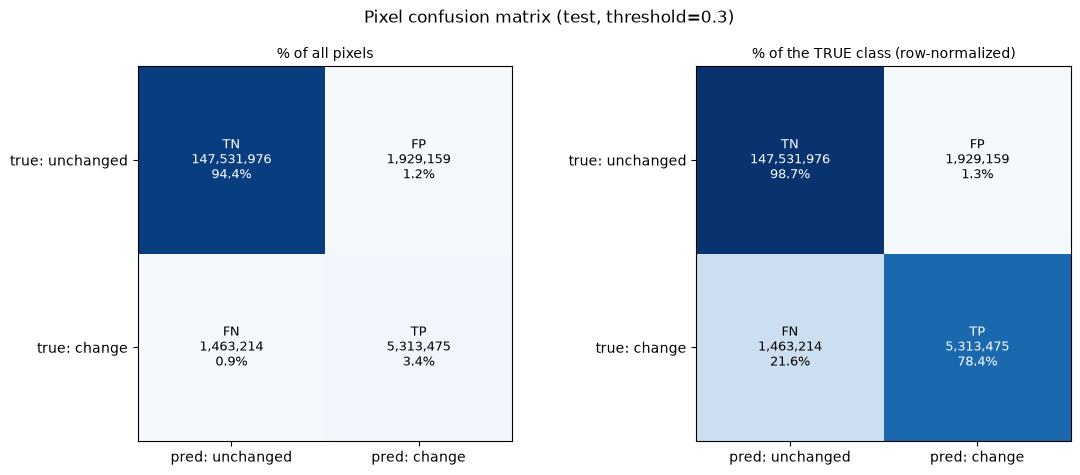

In [4]:
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]], dtype=float)
cm_pct = cm / cm.sum() * 100
cm_row = cm / cm.sum(axis=1, keepdims=True) * 100
labels = [["TN", "FP"], ["FN", "TP"]]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
for ax, mat, title in ((axes[0], cm_pct, "% of all pixels"),
                       (axes[1], cm_row, "% of the TRUE class (row-normalized)")):
    im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i][j]}\n{cm[i,j]:,.0f}\n{mat[i,j]:.1f}%",
                    ha="center", va="center",
                    color="white" if mat[i, j] > 50 else "black", fontsize=9)
    ax.set_xticks([0, 1], ["pred: unchanged", "pred: change"])
    ax.set_yticks([0, 1], ["true: unchanged", "true: change"])
    ax.set_title(title, fontsize=10)
fig.suptitle(f"Pixel confusion matrix (test, threshold={THRESHOLD})")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "confusion_matrix.png", dpi=110)
plt.show()

## 3) أمثلة بصرية: A / B / ground truth / prediction

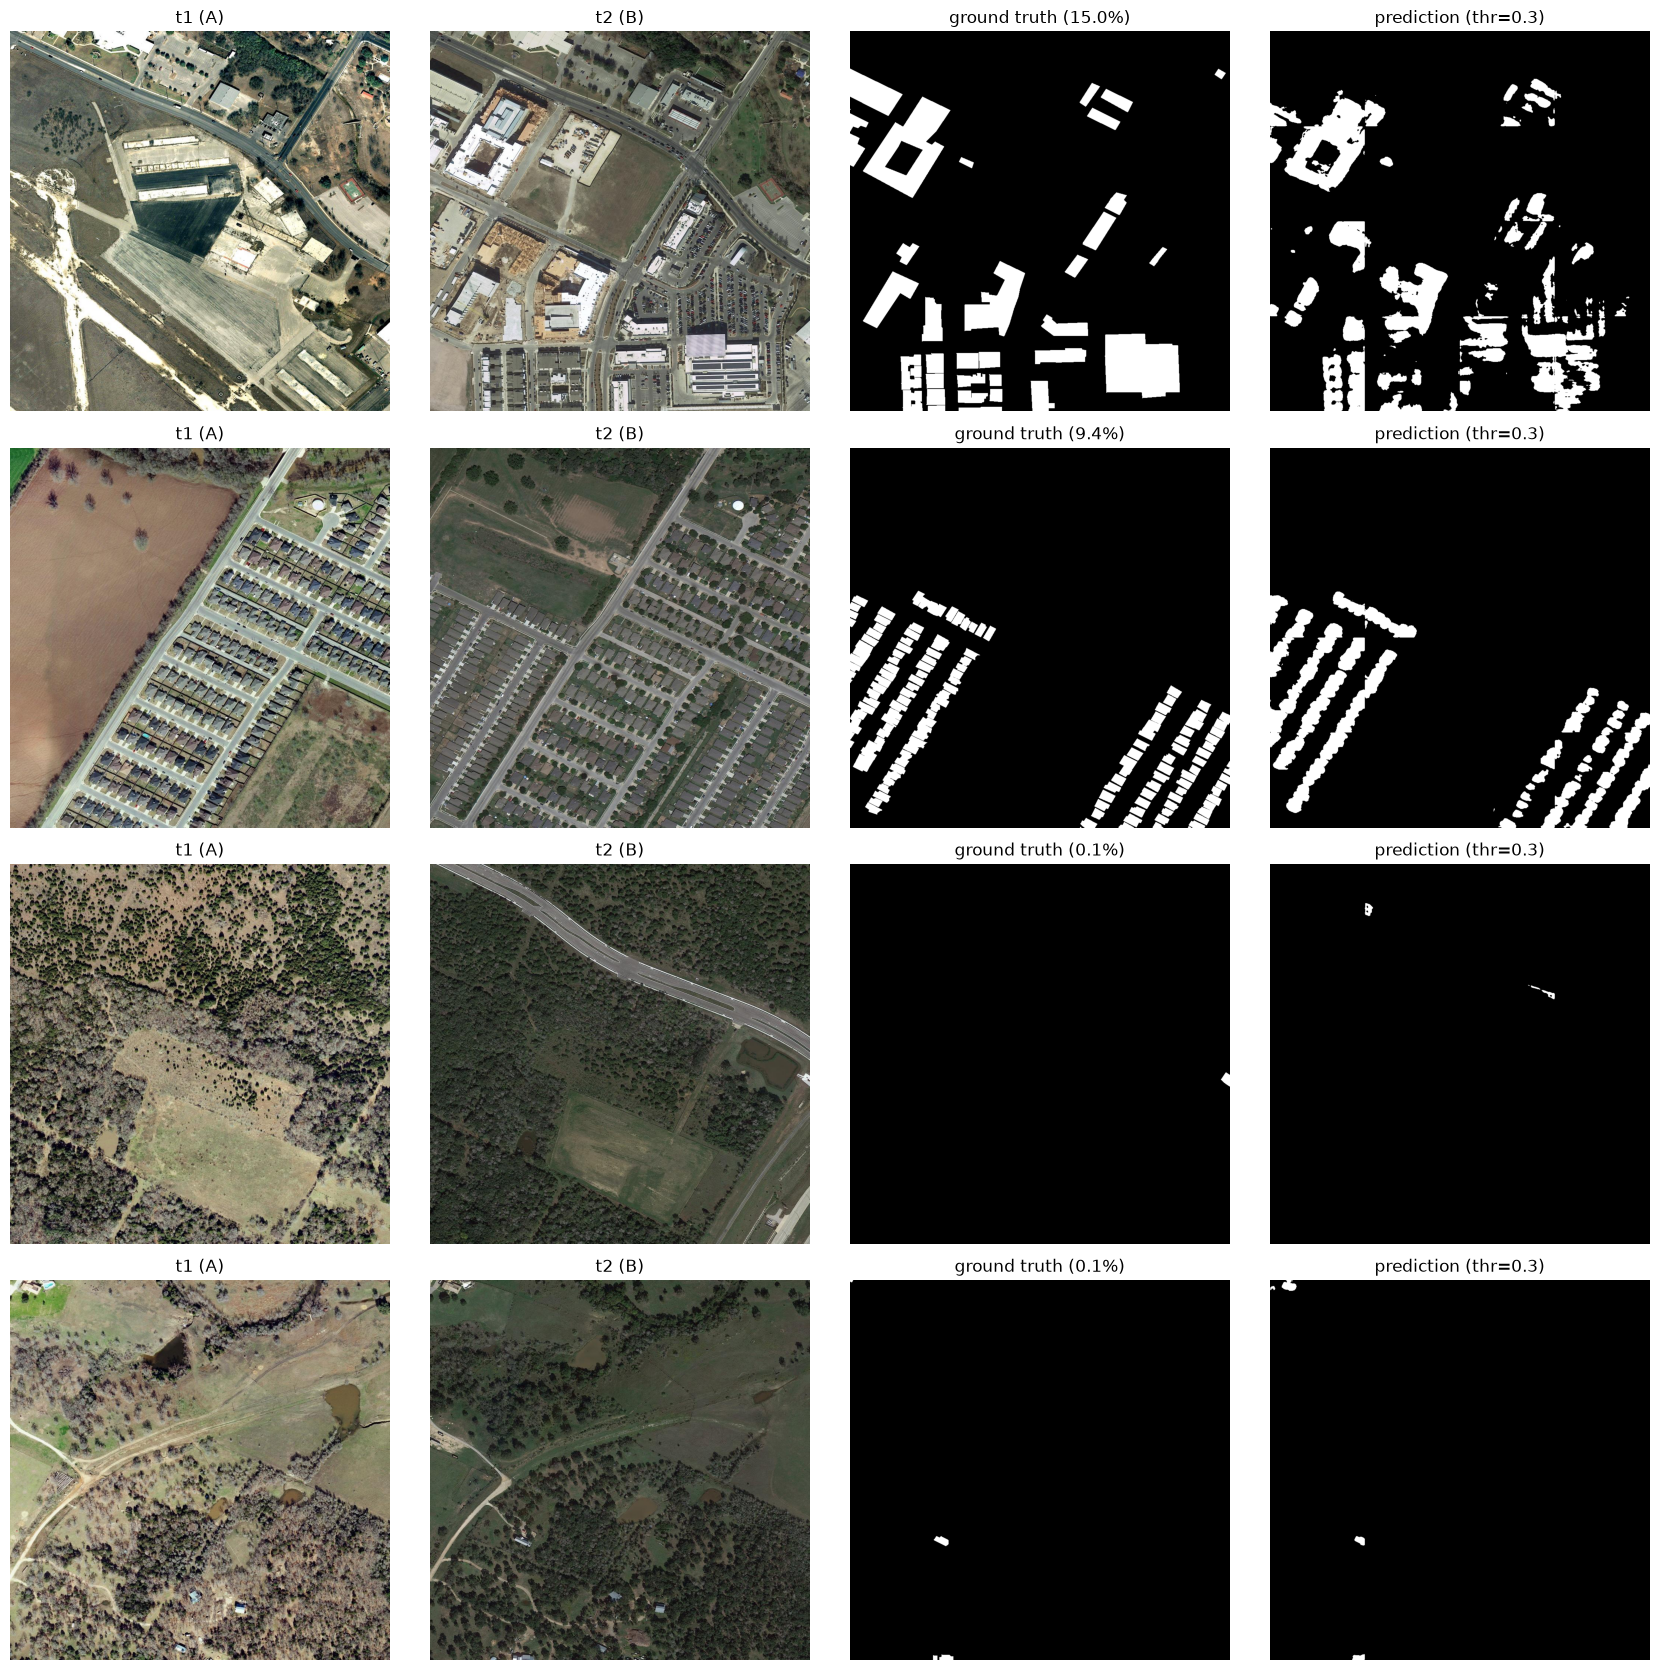

In [5]:
N_VIS = 4
ids = list(range(min(N_VIS, len(test_s))))

canvas = {i: np.zeros((1024, 1024), dtype=np.uint8) for i in ids}
seen = {i: set() for i in ids}
with torch.no_grad():
    for batch in test_dl:
        a = batch["a"].to(device); b = batch["b"].to(device)
        logits = model(a, b).float().cpu()
        metas = batch["meta"]
        for j in range(logits.shape[0]):
            sid = int(metas["sample_idx"][j])
            if sid not in ids:
                continue
            pred = (torch.sigmoid(logits[j, 0]) > THRESHOLD).numpy().astype(np.uint8)
            vh, vw = int(metas["valid_h"][j]), int(metas["valid_w"][j])
            top, left = int(metas["top"][j]), int(metas["left"][j])
            canvas[sid][top:top+vh, left:left+vw] = pred[:vh, :vw]
            seen[sid].add((top, left))
        if all(len(seen[i]) == 16 for i in ids):   # 16 tile لصورة 1024
            break

fig, axes = plt.subplots(len(ids), 4, figsize=(17, 4.2 * len(ids)))
for row, i in enumerate(ids):
    s = test_s[i]
    axes[row, 0].imshow(np.array(Image.open(s.a_path).convert("RGB")))
    axes[row, 0].set_title("t1 (A)")
    axes[row, 1].imshow(np.array(Image.open(s.b_path).convert("RGB")))
    axes[row, 1].set_title("t2 (B)")
    gt = load_mask(s.mask_path)
    axes[row, 2].imshow(gt, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title(f"ground truth ({gt.mean()*100:.1f}%)")
    axes[row, 3].imshow(canvas[i], cmap="gray", vmin=0, vmax=1)
    axes[row, 3].set_title(f"prediction (thr={THRESHOLD})")
    for c in range(4):
        axes[row, c].axis("off")
plt.tight_layout()
plt.show()

In [6]:
# حفظ ملخص النتائج داخل مجلد الـrun
import json
out_dir = run_dir / f"eval_nb_{time.strftime('%Y%m%d_%H%M%S')}"
out_dir.mkdir(parents=True, exist_ok=True)
(out_dir / "test_metrics.json").write_text(
    json.dumps({"threshold": THRESHOLD, **m}, indent=2), encoding="utf-8")
print("saved:", out_dir / "test_metrics.json")

saved: D:\DEPI Project\outputs\run_20261011_073203\eval_nb_20261012_122825\test_metrics.json
